In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("sales_data_sample.csv",
                 encoding="unicode_escape")

print(df.head())
print(df.shape)
print(df.isnull().sum())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

X = X.fillna(X.mean())

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

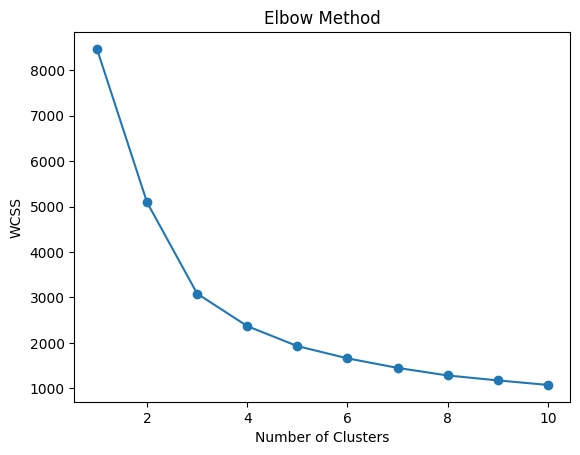

In [5]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42,
                    n_init=10)
    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [6]:
k = 3

kmeans = KMeans(n_clusters=k, random_state=42,
                n_init=10)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['QUANTITYORDERED', 'PRICEEACH',
          'SALES', 'KMeans_Cluster']].head())

   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster
0               30      95.70  2871.00               2
1               34      81.35  2765.90               2
2               41      94.74  3884.34               1
3               45      83.26  3746.70               1
4               49     100.00  5205.27               1


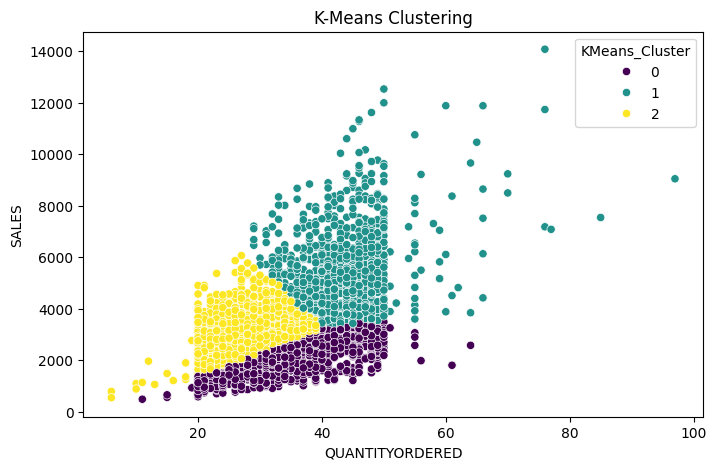

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df['QUANTITYORDERED'],
    y=df['SALES'],
    hue=df['KMeans_Cluster'],
    palette='viridis'
)

plt.title('K-Means Clustering')
plt.show()

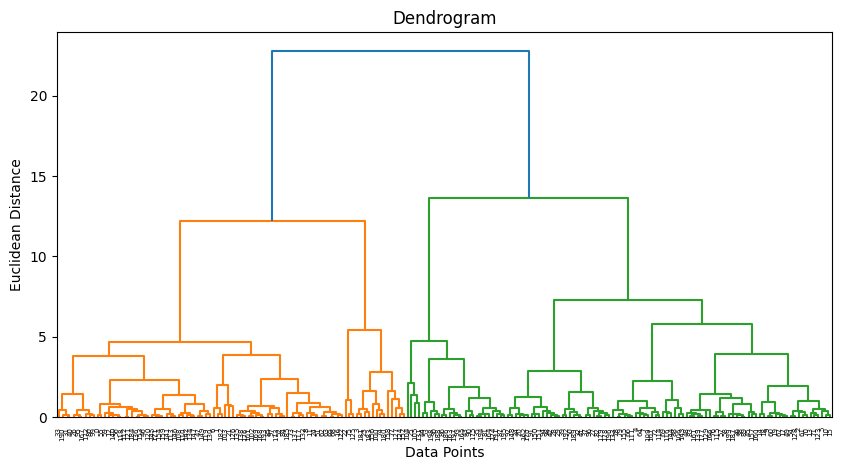

In [8]:
plt.figure(figsize=(10, 5))

Z = linkage(X_scaled[:200], method='ward')

dendrogram(Z)

plt.title('Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')
plt.show()

In [9]:
hc = AgglomerativeClustering(
    n_clusters=k,
    linkage='ward'
)

df['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

print(df[['QUANTITYORDERED', 'PRICEEACH',
          'SALES', 'Hierarchical_Cluster']].head())

   QUANTITYORDERED  PRICEEACH    SALES  Hierarchical_Cluster
0               30      95.70  2871.00                     2
1               34      81.35  2765.90                     2
2               41      94.74  3884.34                     1
3               45      83.26  3746.70                     0
4               49     100.00  5205.27                     1
